In [2]:
import json
from pathlib import Path

DATA_DIR = Path("../../data/v2")

with open(DATA_DIR / "documents.json", encoding="utf-8") as f:
    documents_data = json.load(f)

with open(DATA_DIR / "train.json", encoding="utf-8") as f:
    train_data = json.load(f)

with open(DATA_DIR / "validation.json", encoding="utf-8") as f:
    validation_data = json.load(f)

with open(DATA_DIR / "test.json", encoding="utf-8") as f:
    test_data = json.load(f)

documents = documents_data["documents"]
train_pairs = train_data["pairs"]
validation_pairs = validation_data["pairs"]
test_pairs = test_data["pairs"]

print("Documents :", len(documents))
print("Train     :", len(train_pairs))
print("Validation:", len(validation_pairs))
print("Test      :", len(test_pairs))

Documents : 100
Train     : 1000
Validation: 200
Test      : 200


In [3]:
documents[0]

{'id': 'java-001',
 'category': 'java',
 'title': 'Collections Framework',
 'text': 'Collections Framework is an important java engineering concept used in production software systems. Engineers should understand its purpose, operating behavior, trade-offs, failure modes, configuration, and appropriate use cases. Good implementations rely on measurement, clear boundaries, safe defaults, testing, and operational monitoring rather than treating the technique as a universal solution.'}

In [4]:
train_pairs[0]

{'query': 'explain collections framework', 'document_id': 'java-001'}

###  Create a document lookup

In [5]:
document_lookup = {
    document["id"]: document
    for document in documents
}

In [6]:
document_lookup

{'java-001': {'id': 'java-001',
  'category': 'java',
  'title': 'Collections Framework',
  'text': 'Collections Framework is an important java engineering concept used in production software systems. Engineers should understand its purpose, operating behavior, trade-offs, failure modes, configuration, and appropriate use cases. Good implementations rely on measurement, clear boundaries, safe defaults, testing, and operational monitoring rather than treating the technique as a universal solution.'},
 'java-002': {'id': 'java-002',
  'category': 'java',
  'title': 'HashMap and hashing',
  'text': 'HashMap and hashing is an important java engineering concept used in production software systems. Engineers should understand its purpose, operating behavior, trade-offs, failure modes, configuration, and appropriate use cases. Good implementations rely on measurement, clear boundaries, safe defaults, testing, and operational monitoring rather than treating the technique as a universal solutio

In [7]:
from collections import defaultdict

# Group training pairs by document ID
pairs_by_document = defaultdict(list)

for pair in train_pairs:
    pairs_by_document[pair["document_id"]].append(pair)

# Select 32 unique document IDs
unique_document_ids = list(pairs_by_document.keys())
selected_document_ids = unique_document_ids[:32]

print("Unique documents:", len(unique_document_ids))
print("Selected for one batch:", len(selected_document_ids))
print("Pairs for first selected document:", len(pairs_by_document[selected_document_ids[0]]))

Unique documents: 100
Selected for one batch: 32
Pairs for first selected document: 10


In [8]:
pair = train_pairs[0]

print("QUERY:")
print(pair["query"])

print("\nDOCUMENT ID:")
print(pair["document_id"])

print("\nPOSITIVE DOCUMENT:")
print(document_lookup[pair["document_id"]]["text"])


QUERY:
explain collections framework

DOCUMENT ID:
java-001

POSITIVE DOCUMENT:
Collections Framework is an important java engineering concept used in production software systems. Engineers should understand its purpose, operating behavior, trade-offs, failure modes, configuration, and appropriate use cases. Good implementations rely on measurement, clear boundaries, safe defaults, testing, and operational monitoring rather than treating the technique as a universal solution.


### Build the V2 vocabulary

#### This part is especially interesting compared with V1.We'll build the vocabulary from the training information, rather than test queries For now, keep tokenization deliberately simple:

In [9]:
def tokenize(text):
    return text.lower().split()

### Now collect words from documents and training queries


In [10]:
all_tokens = set()

for document in documents:
    all_tokens.update(tokenize(document["title"]))
    all_tokens.update(tokenize(document["text"]))

for pair in train_pairs:
    all_tokens.update(tokenize(pair["query"]))

    

In [11]:
len(all_tokens) 

505

In [12]:
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

### assign token and index to all the tokens and prepare vocabulary

In [13]:
for token in sorted(all_tokens):
    if token not in vocab:
        vocab[token] = len(vocab)

In [14]:
print("Vocabulary size:", len(vocab))

Vocabulary size: 507


In [15]:
list(vocab.items())[:30]

[('<PAD>', 0),
 ('<UNK>', 1),
 ('2.0', 2),
 ('a', 3),
 ('about', 4),
 ('abstraction', 5),
 ('access', 6),
 ('accessed', 7),
 ('acid', 8),
 ('acquisition', 9),
 ('across', 10),
 ('actions', 11),
 ('actuator', 12),
 ('add', 13),
 ('after', 14),
 ('aggregation', 15),
 ('alerting', 16),
 ('alive', 17),
 ('among', 18),
 ('an', 19),
 ('and', 20),
 ('api', 21),
 ('apis', 22),
 ('application', 23),
 ('appropriate', 24),
 ('architecture', 25),
 ('are', 26),
 ('areas', 27),
 ('as', 28),
 ('asynchronous', 29)]

####  Convert text to token IDs

In [16]:
def text_to_ids(text):
    tokens = tokenize(text)

    return [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

### test it

In [17]:
query = train_pairs[0]["query"]

print("TEXT:")
print(query)

print("\nTOKENS:")
print(tokenize(query))

print("\nTOKEN IDs:")
print(text_to_ids(query))

TEXT:
explain collections framework

TOKENS:
['explain', 'collections', 'framework']

TOKEN IDs:
[162, 84, 175]


In [18]:
print(text_to_ids("supercalifragilistic neural database"))

[1, 1, 121]


### keep your existing text encoder

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class TextEncoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=32,
        output_dim=16
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.projection = nn.Linear(
            embedding_dim,
            output_dim
        )

    def forward(self, token_ids):

        word_vectors = self.embedding(token_ids)

        sentence_vector = word_vectors.mean(dim=1)

        output = self.projection(sentence_vector)

        return F.normalize(output, dim=1)

In [20]:
model = TextEncoder(
    vocab_size=len(vocab),
    embedding_dim=32,
    output_dim=16
)

In [21]:
print(model)

TextEncoder(
  (embedding): Embedding(507, 32)
  (projection): Linear(in_features=32, out_features=16, bias=True)
)


In [22]:
for name, parameter in model.named_parameters():
    print(
        name,
        tuple(parameter.shape),
        parameter.numel()
    )

embedding.weight (507, 32) 16224
projection.weight (16, 32) 512
projection.bias (16,) 16


### inspect V2 model before proceeding

In [23]:
print("Vocabulary size:", len(vocab))

print("Embedding matrix:")
print(model.embedding.weight.shape)

print("Total parameters:")
print(sum(p.numel() for p in model.parameters()))

Vocabulary size: 507
Embedding matrix:
torch.Size([507, 32])
Total parameters:
16752


####  Create padded batches

In [24]:
from torch.nn.utils.rnn import pad_sequence
def texts_to_padded_tensor(texts):

    sequences = [
        torch.tensor(
            text_to_ids(text),
            dtype=torch.long
        )
        for text in texts
    ]

    return pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab["<PAD>"]
    )

In [25]:
sample_texts = [
    "explain application caching",
    "how does database connection pooling work",
    "best practices for oauth 2.0"
]

sample_batch = texts_to_padded_tensor(sample_texts)

print(sample_batch)
print(sample_batch.shape)

tensor([[162,  23,  59,   0,   0,   0],
        [194, 139, 121, 100, 329, 504],
        [ 48, 330, 174, 289,   2,   0]])
torch.Size([3, 6])


###  Upgrade TextEncoder to masked mean pooling(to avoid <PAD> : 0 get included in calculation).it prevents padding from participating in sentence averaging.

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TextEncoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=32,
        output_dim=16,
        padding_idx=0
    ):
        super().__init__()

        self.padding_idx = padding_idx

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        self.projection = nn.Linear(
            embedding_dim,
            output_dim
        )

    def forward(self, token_ids):

        # [batch, tokens, 32]
        word_vectors = self.embedding(token_ids)

        # True for real tokens, False for PAD
        # [batch, tokens]
        mask = token_ids != self.padding_idx

        # [batch, tokens, 1]
        mask = mask.unsqueeze(-1).float()

        # PAD vectors contribute zero
        masked_vectors = word_vectors * mask

        # [batch, 32]
        summed_vectors = masked_vectors.sum(dim=1)

        # Number of real tokens in each sentence
        # [batch, 1]
        token_counts = mask.sum(dim=1).clamp(min=1)

        # Mean of REAL tokens only
        sentence_vector = summed_vectors / token_counts

        # [batch, 16]
        output = self.projection(sentence_vector)

        # unit-length vectors
        return F.normalize(output, dim=1)

### Verify padding doesn't alter the representation

In [27]:
model = TextEncoder(
    vocab_size=len(vocab),
    embedding_dim=32,
    output_dim=16,
    padding_idx=vocab["<PAD>"]
)

model.eval()

TextEncoder(
  (embedding): Embedding(507, 32, padding_idx=0)
  (projection): Linear(in_features=32, out_features=16, bias=True)
)

### Now encode the same sentence in two forms:

In [28]:
ids = text_to_ids("application caching")

normal = torch.tensor([
    ids
])

padded = torch.tensor([
    ids + [0, 0, 0, 0, 0]
])

padded


tensor([[23, 59,  0,  0,  0,  0,  0]])

In [29]:
with torch.no_grad():

    vector_normal = model(normal)
    vector_padded = model(padded)

print("NORMAL:")
print(vector_normal)

print("\nPADDED:")
print(vector_padded)

print("\nMAX DIFFERENCE:")
print(
    (vector_normal - vector_padded)
    .abs()
    .max()
    .item()
)

NORMAL:
tensor([[ 0.1216, -0.0018,  0.1029, -0.3275, -0.0701,  0.1968,  0.2529,  0.5277,
          0.0156, -0.3243,  0.1255,  0.1954,  0.2430, -0.2231, -0.1887, -0.4212]])

PADDED:
tensor([[ 0.1216, -0.0018,  0.1029, -0.3275, -0.0701,  0.1968,  0.2529,  0.5277,
          0.0156, -0.3243,  0.1255,  0.1954,  0.2430, -0.2231, -0.1887, -0.4212]])

MAX DIFFERENCE:
0.0


### Now create the training Dataset

In [30]:
from torch.utils.data import Dataset


class SearchDataset(Dataset):

    def __init__(
        self,
        pairs,
        document_lookup
    ):
        self.pairs = pairs
        self.document_lookup = document_lookup

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        pair = self.pairs[index]

        query = pair["query"]

        document_id = pair["document_id"]

        document = self.document_lookup[
            document_id
        ]

        return {
            "query": query,
            "document_id": document_id,
            "document_text": document["text"]
        }

In [31]:
train_dataset = SearchDataset(
    train_pairs,
    document_lookup
)

In [32]:
print(len(train_dataset))
print(train_dataset[0])

1000
{'query': 'explain collections framework', 'document_id': 'java-001', 'document_text': 'Collections Framework is an important java engineering concept used in production software systems. Engineers should understand its purpose, operating behavior, trade-offs, failure modes, configuration, and appropriate use cases. Good implementations rely on measurement, clear boundaries, safe defaults, testing, and operational monitoring rather than treating the technique as a universal solution.'}


### Create the collate function
#### This is where individual variable-length examples become one rectangular batch.

In [33]:
def collate_batch(batch):

    queries = [
        item["query"]
        for item in batch
    ]

    documents = [
        item["document_text"]
        for item in batch
    ]

    document_ids = [
        item["document_id"]
        for item in batch
    ]

    query_tensor = texts_to_padded_tensor(
        queries
    )

    document_tensor = texts_to_padded_tensor(
        documents
    )

    return {
        "queries": query_tensor,
        "documents": document_tensor,
        "document_ids": document_ids,
        "query_texts": queries
    }

### Introduce DataLoader


In [34]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate_batch
)

In [35]:
print(len(train_loader))

32


#### Inspect one real batch. Do this before training

In [36]:
batch = next(iter(train_loader))

print("QUERY TENSOR:")
print(batch["queries"])

print("\nQUERY SHAPE:")
print(batch["queries"].shape)

print("Document TENSOR:")
print(batch["documents"])

print("\nDOCUMENT SHAPE:")
print(batch["documents"].shape)

QUERY TENSOR:
tensor([[194, 136, 197, 207, 243, 339,   0,   0,   0,   0,   0],
        [495, 412, 197, 240,   4,  29, 337,   0,   0,   0,   0],
        [ 48, 330, 174, 172, 298, 368,  10, 269, 408,   0,   0],
        [192, 271, 477,  65, 323,   0,   0,   0,   0,   0,   0],
        [194, 139, 153, 397, 157, 504,   0,   0,   0,   0,   0],
        [194, 136, 197, 207, 241, 130,   0,   0,   0,   0,   0],
        [ 48, 330, 174,  96, 268,   0,   0,   0,   0,   0,   0],
        [162, 155,  25,   0,   0,   0,   0,   0,   0,   0,   0],
        [194, 136, 197, 207, 275, 379, 436,   0,   0,   0,   0],
        [495, 412, 197, 240,   4, 316, 188,   0,   0,   0,   0],
        [338, 102, 174,  43, 488,   0,   0,   0,   0,   0,   0],
        [338, 102, 174, 425, 402,   0,   0,   0,   0,   0,   0],
        [495, 335, 139, 163,  96, 421,   0,   0,   0,   0,   0],
        [194, 139, 158, 186, 504,   0,   0,   0,   0,   0,   0],
        [194, 136, 197, 207, 316, 188,   0,   0,   0,   0,   0],
        [19

## We have moved to V2

```
1,000 training examples
          ↓
       Dataset
          ↓
      DataLoader
          ↓
       shuffle
          ↓
     batch of 32
          ↓
        padding
          ↓
         mask
          ↓
       Embedding
          ↓
   masked mean pooling
          ↓
     32 → 16 projection
          ↓
   normalized embeddings 

   ```

### But we still haven't trained anything yet.That's intentional.Run through this and particularly check these four outputs:

In [38]:
print("Number of batches:", len(train_loader))

batch = next(iter(train_loader))

print("Query batch shape:", batch["queries"].shape)
print("Document batch shape:", batch["documents"].shape)

print(
    "Padding test max difference:",
    (vector_normal - vector_padded)
    .abs()
    .max()
    .item()
)

Number of batches: 32
Query batch shape: torch.Size([32, 11])
Document batch shape: torch.Size([32, 53])
Padding test max difference: 0.0


### our next step is the really interesting V2 part: instead of manually choosing one negative document, we'll construct the 32 × 32 query-document similarity matrix and use the other documents in the batch as negatives. That's where the training begins to resemble a proper contrastive semantic-search model.


## V2 — Query–Document Similarity Matrix

Objective:
1. Select 32 query-document pairs.
2. Encode queries and documents using the same TextEncoder.
3. Generate 16-dimensional vectors.
4. Calculate a 32 × 32 cosine similarity matrix.
5. Identify positive and negative document relationships.

Note: Different training queries may refer to the same document.
For this experiment, select unique document IDs to avoid
incorrectly treating duplicate positive documents as negatives.

Code: Prepare 32 unique query–document pairs

In [39]:
import random
from collections import defaultdict

# Group training pairs by document ID
pairs_by_document = defaultdict(list)

for pair in train_pairs:
    pairs_by_document[pair["document_id"]].append(pair)

# Select 32 unique document IDs
selected_document_ids = random.sample(
    list(pairs_by_document.keys()),
    k=32
)

# Select one query per document
selected_pairs = [
    random.choice(pairs_by_document[doc_id])
    for doc_id in selected_document_ids
]

# Reuse your existing Dataset
experiment_dataset = SearchDataset(
    selected_pairs,
    document_lookup
)

# Reuse your existing collate function
batch = collate_batch([
    experiment_dataset[i]
    for i in range(len(experiment_dataset))
])

print("Query batch:", batch["queries"].shape)
print("Document batch:", batch["documents"].shape)

print("Unique documents:", len(set(batch["document_ids"])))

Query batch: torch.Size([32, 12])
Document batch: torch.Size([32, 51])
Unique documents: 32


###  Generate query and document vectors.  This will confirms that both query and document text have been converted into 16-dimensional vectors.

In [40]:
model.eval()

with torch.no_grad():

    query_vectors = model(
        batch["queries"]
    )

    document_vectors = model(
        batch["documents"]
    )

print("Query vectors:", query_vectors.shape)
print("Document vectors:", document_vectors.shape)

Query vectors: torch.Size([32, 16])
Document vectors: torch.Size([32, 16])


###  Calculate the similarity matrix

In [42]:
similarity_matrix = (
    query_vectors @ document_vectors.T
)

print("Similarity matrix shape:")
print(similarity_matrix.shape)

print("\nFirst 5 × 5 similarities:")
print(similarity_matrix[:32, :32])

Similarity matrix shape:
torch.Size([32, 32])

First 5 × 5 similarities:
tensor([[0.3477, 0.3172, 0.2821,  ..., 0.2142, 0.3021, 0.2892],
        [0.2228, 0.4290, 0.2531,  ..., 0.2496, 0.2752, 0.3136],
        [0.5124, 0.5640, 0.5119,  ..., 0.4876, 0.5305, 0.5727],
        ...,
        [0.0147, 0.1819, 0.0757,  ..., 0.1602, 0.0754, 0.1774],
        [0.3251, 0.3043, 0.3026,  ..., 0.2174, 0.3514, 0.2434],
        [0.3303, 0.4066, 0.3327,  ..., 0.3579, 0.3705, 0.4878]])


###   Visualize the similarity matrix

In [43]:
import pandas as pd

similarity_df = pd.DataFrame(
    similarity_matrix.numpy(),
    index=[f"Q{i}" for i in range(32)],
    columns=[f"D{i}" for i in range(32)]
)

display(
    similarity_df.style
    .format("{:.3f}")
    .background_gradient(cmap="YlGnBu")
)

,D0,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,D16,D17,D18,D19,D20,D21,D22,D23,D24,D25,D26,D27,D28,D29,D30,D31
Q0,0.348,0.317,0.282,0.206,0.289,0.324,0.271,0.210,0.326,0.309,0.255,0.221,0.227,0.176,0.349,0.250,0.199,0.498,0.249,0.230,0.231,0.220,0.260,0.601,0.228,0.232,0.258,0.224,0.229,0.214,0.302,0.289
Q1,0.223,0.429,0.253,0.156,0.321,0.291,0.319,0.275,0.298,0.306,0.249,0.276,0.364,0.315,0.283,0.362,0.265,0.401,0.221,0.193,0.351,0.332,0.179,0.282,0.333,0.257,0.320,0.345,0.293,0.250,0.275,0.314
Q2,0.512,0.564,0.512,0.436,0.520,0.491,0.534,0.465,0.591,0.560,0.475,0.484,0.538,0.500,0.515,0.538,0.476,0.482,0.471,0.475,0.486,0.486,0.490,0.609,0.529,0.513,0.487,0.484,0.503,0.488,0.531,0.573
Q3,0.317,0.230,0.335,0.397,0.189,0.281,0.258,0.271,0.287,0.244,0.277,0.244,0.190,0.239,0.304,0.224,0.234,0.404,0.246,0.276,0.161,0.224,0.328,0.427,0.198,0.243,0.274,0.248,0.226,0.271,0.337,0.206
Q4,0.057,0.148,0.071,-0.019,0.268,0.070,0.150,0.100,0.155,0.086,0.072,0.111,0.155,0.125,0.084,0.118,0.132,-0.217,0.174,0.070,0.218,0.161,0.029,0.065,0.103,0.079,0.161,0.124,0.123,0.053,0.076,0.195
Q5,0.269,0.300,0.265,0.176,0.261,0.365,0.274,0.270,0.247,0.240,0.322,0.303,0.181,0.248,0.356,0.323,0.170,0.693,0.206,0.154,0.196,0.237,0.201,0.538,0.248,0.195,0.262,0.279,0.233,0.203,0.334,0.265
Q6,0.110,0.132,0.103,0.108,0.126,0.034,0.180,0.048,0.221,0.146,0.060,0.068,0.194,0.199,0.028,0.090,0.178,-0.160,0.159,0.109,0.128,0.109,0.082,0.173,0.130,0.110,0.065,0.064,0.174,0.128,0.101,0.208
Q7,0.001,0.046,0.014,-0.094,0.010,0.018,0.012,0.074,0.028,-0.001,-0.003,-0.038,0.044,-0.050,-0.005,0.014,-0.019,0.229,-0.074,0.031,0.016,-0.007,-0.016,0.338,-0.015,-0.053,0.067,-0.073,-0.042,-0.045,-0.017,-0.046
Q8,0.255,0.253,0.297,0.248,0.269,0.237,0.294,0.268,0.368,0.242,0.247,0.210,0.226,0.266,0.253,0.240,0.237,0.261,0.257,0.222,0.193,0.209,0.250,0.550,0.223,0.223,0.286,0.185,0.234,0.219,0.300,0.281
Q9,0.129,0.276,0.199,0.132,0.142,0.225,0.192,0.162,0.205,0.235,0.206,0.214,0.184,0.248,0.223,0.296,0.123,0.549,0.096,0.085,0.124,0.153,0.124,0.238,0.254,0.220,0.185,0.252,0.184,0.222,0.221,0.246


###  Inspect the top five documents for one query

In [44]:
query_index = 0

print("Query:")
print(batch["query_texts"][query_index])

print("\nCorrect document:")
print(batch["document_ids"][query_index])

scores = similarity_matrix[query_index]

top_indices = torch.argsort(
    scores,
    descending=True
)[:5]

print("\nTop 5 matching documents:")

for rank, idx in enumerate(top_indices, start=1):

    idx = idx.item()

    print(
        f"{rank}. "
        f"{batch['document_ids'][idx]} "
        f"| Similarity: {scores[idx].item():.4f}"
    )

Query:
what problem does spring data jpa solve

Correct document:
spring-005

Top 5 matching documents:
1. security-001 | Similarity: 0.6009
2. database-001 | Similarity: 0.4980
3. containers-008 | Similarity: 0.3490
4. spring-005 | Similarity: 0.3477
5. aws-003 | Similarity: 0.3256


###  Calculate contrastive loss. Now we introduce the first learning objective.This calculates the initial loss for the batch.Important: Since the earlier vectors were calculated under torch.no_grad(), this loss is only for inspection. It cannot be used directly for backpropagation.

In [45]:
import torch.nn.functional as F

temperature = 0.07

# Convert similarities into logits
logits = similarity_matrix / temperature

# Correct document for query i is document i
targets = torch.arange(
    similarity_matrix.shape[0]
)

loss = F.cross_entropy(
    logits,
    targets
)

print("Targets:", targets)
print("Initial contrastive loss:", loss.item())

Targets: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
Initial contrastive loss: 3.451129913330078


###  Perform one actual training step.Now recalculate the forward pass with gradient tracking enabled.

In [46]:
model.train()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# Save weights before update
embedding_before = model.embedding.weight.detach().clone()
projection_before = model.projection.weight.detach().clone()

optimizer.zero_grad()

# Forward pass WITH gradient tracking
q_vectors = model(batch["queries"])
d_vectors = model(batch["documents"])

similarities = q_vectors @ d_vectors.T

logits = similarities / temperature

loss_before = F.cross_entropy(
    logits,
    targets
)

# Calculate gradients
loss_before.backward()

print("Loss before update:", loss_before.item())

print(
    "Embedding gradient:",
    model.embedding.weight.grad.abs().max().item()
)

# Update weights
optimizer.step()

# Compare weights
embedding_change = (
    model.embedding.weight.detach() - embedding_before
)

projection_change = (
    model.projection.weight.detach() - projection_before
)

print(
    "Maximum embedding weight change:",
    embedding_change.abs().max().item()
)

print(
    "Maximum projection weight change:",
    projection_change.abs().max().item()
)

Loss before update: 3.451129913330078
Embedding gradient: 0.10765957087278366
Maximum embedding weight change: 0.0010765790939331055
Maximum projection weight change: 0.010864242911338806


###  above completes one genuine training step.

### Compare loss after training

In [47]:
model.eval()

with torch.no_grad():

    q_after = model(batch["queries"])
    d_after = model(batch["documents"])

    similarities_after = q_after @ d_after.T

    loss_after = F.cross_entropy(
        similarities_after / temperature,
        targets
    )

print("Loss before:", loss_before.item())
print("Loss after :", loss_after.item())

print(
    "Difference:",
    loss_before.item() - loss_after.item()
)

Loss before: 3.451129913330078
Loss after : 3.0763814449310303
Difference: 0.37474846839904785


### above shows the loss may decrease after this step, although one update does not guarantee an improvement.

``` Where we will be after these cells
Notebook cells	Purpose
0–52	Existing V2 preparation and experiments
53–54	Prepare controlled batch with unique documents
55–56	Generate embeddings and similarity matrix
57–58	Visualize and inspect retrieval rankings
59	Calculate initial contrastive loss
60	Backpropagation and weight update
61	Compare loss before and after training
My recommendation: Implement cells 53–59 first and inspect the similarity matrix and initial loss. Then run cells 60–61 to observe the weight changes.
After this, we'll be ready for the full multi-epoch training loop, followed by validation using Recall@1, Recall@3, Recall@5, and MRR. ```

### V2 Neural Search — Next Step: Train Across Multiple Epochs.Now we'll move from one training update to a complete training loop, then evaluate whether your model can retrieve the correct engineering document for a query.
### I'm continuing with your existing v2_training.ipynb design: the 507-token vocabulary, masked-mean TextEncoder, 32-dimensional token embeddings, 16-dimensional sentence vectors, and the existing SearchDataset and collate_batch() functions. We'll append new cells rather than replace your experiments. 

### What we're implementing
``` 100 unique documents
Select one training query for each document

4 batches per epoch
Batch size = 25; unique document IDs within each batch

Contrastive loss → backward → optimizer step

Repeat for 50 epochs

Evaluate retrieval quality
Recall@1, Recall@3, Recall@5 and MRR```




##### One design decision matters here: your 1,000 training pairs refer to only 100 documents, with multiple queries per document. For this first implementation, we'll randomly select one query per document in each epoch. That avoids duplicate positive document IDs within a batch, which makes the diagonal-target loss valid for this experiment.

## V2 — Full Training Loop

We will train the TextEncoder using in-batch contrastive learning.

For each epoch:
1. Select one query per unique document.
2. Shuffle the 100 query-document pairs.
3. Process four batches of 25 pairs.
4. Calculate the similarity matrix and contrastive loss.
5. Backpropagate gradients and update model parameters.
6. Record the average training loss.

We will then evaluate retrieval using the separate validation set.

###  Prepare reproducible training data

In [48]:
import random
import torch
import torch.nn.functional as F
from collections import defaultdict

random.seed(42)
torch.manual_seed(42)

# Group training queries by their correct document
pairs_by_document = defaultdict(list)

for pair in train_pairs:
    pairs_by_document[pair["document_id"]].append(pair)

print("Unique training documents:", len(pairs_by_document))
print("Training query pairs:", len(train_pairs))

Unique training documents: 100
Training query pairs: 1000


####  cell 50-56 is more of visualisation of data and not part of model training

In [50]:
import pandas as pd
from IPython.display import display

# Convert the list of dictionaries into a DataFrame
train_pairs_df = pd.DataFrame(train_pairs)

# Display the first 10 query-document pairs
display(train_pairs_df.head(15))

print("Total training pairs:", len(train_pairs))
print("\nColumns:", train_pairs_df.columns.tolist())
print("\nData types:")
print(train_pairs_df.dtypes)

,query,document_id
0,explain collections framework,java-001
1,how does collections framework work,java-001
2,what should I know about collections framework,java-001
3,when should I use collections framework,java-001
4,help me understand collections framework,java-001
5,best practices for collections framework,java-001
6,how do I implement collections framework,java-001
7,what problem does collections framework solve,java-001
8,give me guidance on collections framework,java-001
9,production considerations for collections fram...,java-001


Total training pairs: 1000

Columns: ['query', 'document_id']

Data types:
query          str
document_id    str
dtype: object


#####   Visualize pairs_by_document

In [51]:
grouped_rows = []

for doc_id, pairs in pairs_by_document.items():
    for pair_number, pair in enumerate(pairs, start=1):
        grouped_rows.append({
            "document_id": doc_id,
            "query_number": pair_number,
            "query": pair["query"]
        })

pairs_by_document_df = pd.DataFrame(grouped_rows)

display(pairs_by_document_df.head(20))

,document_id,query_number,query
0,java-001,1,explain collections framework
1,java-001,2,how does collections framework work
2,java-001,3,what should I know about collections framework
3,java-001,4,when should I use collections framework
4,java-001,5,help me understand collections framework
5,java-001,6,best practices for collections framework
6,java-001,7,how do I implement collections framework
7,java-001,8,what problem does collections framework solve
8,java-001,9,give me guidance on collections framework
9,java-001,10,production considerations for collections fram...


#### Summarize how many queries each document has


In [52]:
query_counts_df = (
    train_pairs_df
    .groupby("document_id")
    .size()
    .reset_index(name="number_of_queries")
    .sort_values("number_of_queries", ascending=False)
)

display(query_counts_df)

,document_id,number_of_queries
0,aws-001,10
63,observability-004,10
73,performance-004,10
72,performance-003,10
71,performance-002,10
...,...,...
30,java-001,10
29,database-010,10
28,database-009,10
27,database-008,10


#### Visualize the distribution with a bar chart:

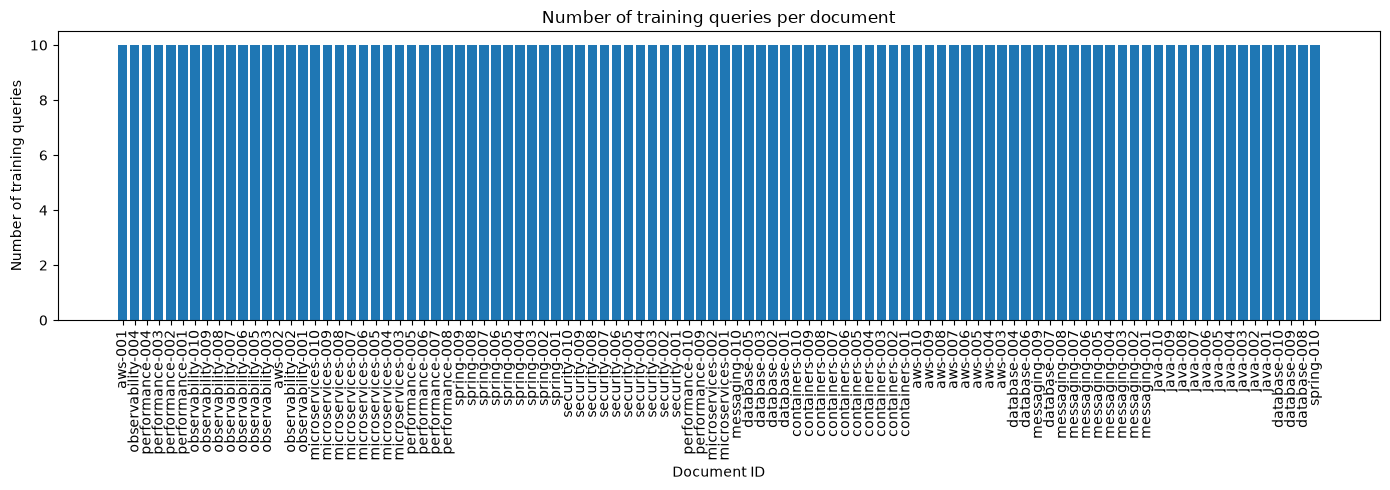

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.bar(
    query_counts_df["document_id"].astype(str),
    query_counts_df["number_of_queries"]
)

plt.xlabel("Document ID")
plt.ylabel("Number of training queries")
plt.title("Number of training queries per document")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

####   Inspect one complete group.This is the most useful step for understanding why we created pairs_by_document.


In [56]:
# Get the first document ID from the grouped dictionary
sample_doc_id = next(iter(pairs_by_document))

print("Document ID:", sample_doc_id)
print("Number of associated queries:",
      len(pairs_by_document[sample_doc_id]))

for i, pair in enumerate(
    pairs_by_document[sample_doc_id], start=1
):
    print(f"{i}. Query: {pair['query']}")

Document ID: java-001
Number of associated queries: 10
1. Query: explain collections framework
2. Query: how does collections framework work
3. Query: what should I know about collections framework
4. Query: when should I use collections framework
5. Query: help me understand collections framework
6. Query: best practices for collections framework
7. Query: how do I implement collections framework
8. Query: what problem does collections framework solve
9. Query: give me guidance on collections framework
10. Query: production considerations for collections framework


####  The example above is illustrative; your actual output will show the values in your dataset.
The key distinction:
- train_pairs is the original list containing all training examples.
- pairs_by_document is a dictionary that groups those same examples by their document_id.
- No training pairs are removed or modified during grouping.
For example, if one document has 10 associated queries, its entry in pairs_by_document contains a list of all 10 pairs. Later, random.choice(pairs) can select one of those queries for a particular training epoch.

### Now create a helper that selects one query for every document:

In [61]:
def create_epoch_pairs(pairs_by_document):
    epoch_pairs = [
        random.choice(pairs)
        for pairs in pairs_by_document.values()
    ]

    random.shuffle(epoch_pairs)
    return epoch_pairs

###  Every epoch gets 100 pairs, and the selected query for a document can change between epochs.


#### Initialize a fresh model and optimizer.If you've already run the previous one-step experiment, reset the model here so that this is a clean, reproducible training run.

In [59]:
model = TextEncoder(
    vocab_size=len(vocab),
    embedding_dim=32,
    output_dim=16,
    padding_idx=vocab["<PAD>"]
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

BATCH_SIZE = 25
TEMPERATURE = 0.07
EPOCHS = 50

print("Parameters:",
      sum(p.numel() for p in model.parameters()))

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Parameters: 16752
Batch size: 25
Epochs: 50


## Training Loss

The screenshot below shows the training loss across epochs.

## Training Loss

The screenshot below shows the training loss across epochs.

![explain Parameters: 16752 Batch size: 25 Epochs: 50](../../data/v2/docs/images/training_parametrs.png)
![batch](../../data/v2/docs/images/training_and_batch.png)
![batch](../../data/v2/docs/images/batch_explanation.png)
![epoch](../../data/v2/docs/images/epoch1.png)
![epoch](../../data/v2/docs/images/epoch2.png)

The screenshot below shows the how 3 components 16275 parameters (vocab+projection+bias), weight adjustment with training and search works 

![explain Parameters: 16752 Batch size: 25 Epochs: 50](../../data/v2/docs/images/t1.png)
![batch](../../data/v2/docs/images/t2.png)
![batch](../../data/v2/docs/images/t3.png)
![epoch](../../data/v2/docs/images/t4.png)
![epoch](../../data/v2/docs/images/t5.png)

####    Run the full training loop

This cell will finally train the model across all 50 epochs.

#### What should you expect?
For your current dataset:
- 100 unique documents produce 100 selected query-document pairs per epoch.
- Each epoch has 4 batches of 25 pairs.
- 50 epochs result in 200 optimizer updates.
- training_losses stores one average loss value per epoch.
The loss may fluctuate, but we generally want to see a downward trend.

In [91]:
training_losses = []

for epoch in range(EPOCHS):

    model.train()

    # Select one query for each of the 100 documents
    epoch_pairs = create_epoch_pairs(pairs_by_document)
    #print(epoch_pairs)
    #print(len(epoch_pairs))
    total_loss = 0.0
    total_pairs = 0

    # # Divide the 100 pairs into batches of 25
    for start in range(0, len(epoch_pairs), BATCH_SIZE):

        pair_batch = epoch_pairs[start:start + BATCH_SIZE]
        
    # Convert this batch into padded query/document tensors
        batch_dataset = SearchDataset(
            pair_batch,
            document_lookup
        )

        batch = collate_batch([
            batch_dataset[i]
            for i in range(len(batch_dataset))
        ])

        # Verify that every document ID is unique in this batch
        assert len(batch["document_ids"]) == len(
            set(batch["document_ids"])
        )

        # 1. Clear gradients from the previous update
        optimizer.zero_grad()

        # 2. Forward pass: create 16-dimensional vectors
        query_vectors = model(batch["queries"])
        document_vectors = model(batch["documents"])

        # 3. Compare every query against every document
        similarities = query_vectors @ document_vectors.T

        # 4. Scale the similarity scores
        logits = similarities / TEMPERATURE

        # 5. The correct match is on the diagonal
        targets = torch.arange(len(pair_batch))

        # 6. Calculate contrastive loss
        loss = F.cross_entropy(logits, targets)

        # 7. Calculate gradients
        loss.backward()

        # 8. Update the model's parameters
        optimizer.step()

        total_loss += loss.item() * len(pair_batch)
        total_pairs += len(pair_batch)

    average_loss = total_loss / total_pairs
    training_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Training loss: {average_loss:.4f}"
    )

Epoch 01/50 | Training loss: 0.0130
Epoch 02/50 | Training loss: 0.0118
Epoch 03/50 | Training loss: 0.0099
Epoch 04/50 | Training loss: 0.0109
Epoch 05/50 | Training loss: 0.0129
Epoch 06/50 | Training loss: 0.0120
Epoch 07/50 | Training loss: 0.0137
Epoch 08/50 | Training loss: 0.0102
Epoch 09/50 | Training loss: 0.0105
Epoch 10/50 | Training loss: 0.0141
Epoch 11/50 | Training loss: 0.0126
Epoch 12/50 | Training loss: 0.0110
Epoch 13/50 | Training loss: 0.0119
Epoch 14/50 | Training loss: 0.0121
Epoch 15/50 | Training loss: 0.0110
Epoch 16/50 | Training loss: 0.0125
Epoch 17/50 | Training loss: 0.0147
Epoch 18/50 | Training loss: 0.0112
Epoch 19/50 | Training loss: 0.0102
Epoch 20/50 | Training loss: 0.0085
Epoch 21/50 | Training loss: 0.0106
Epoch 22/50 | Training loss: 0.0102
Epoch 23/50 | Training loss: 0.0108
Epoch 24/50 | Training loss: 0.0146
Epoch 25/50 | Training loss: 0.0111
Epoch 26/50 | Training loss: 0.0107
Epoch 27/50 | Training loss: 0.0108
Epoch 28/50 | Training loss:

#### After training: visualize the loss

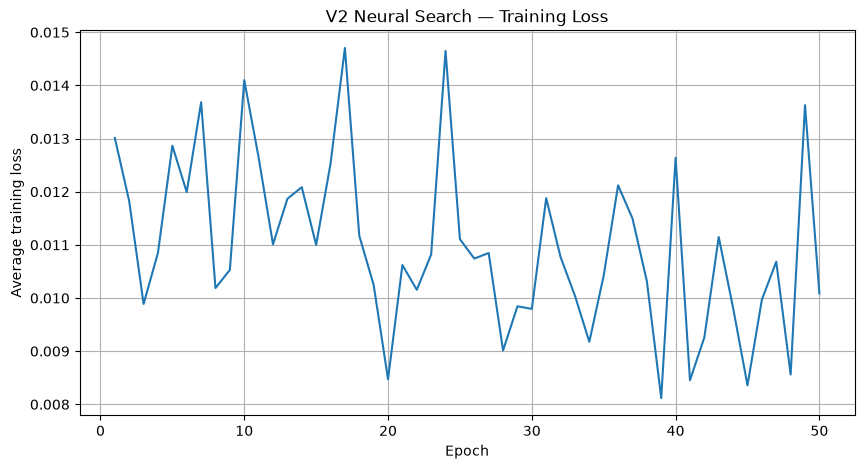

In [92]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), training_losses)

plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("V2 Neural Search — Training Loss")
plt.grid(True)
plt.show()

####  Let's validate the model you have trained before changing its architecture or increasing the number of epochs.
We'll do this in your existing v2_training.ipynb notebook, one step at a time:
1. Encode all 100 documents into 16-dimensional vectors using the trained model.
2. Encode each of the 200 validation queries.
3. Compare every query against all 100 document vectors.
4. Rank the documents by similarity and check where the expected relevant document appears.
5. Calculate Recall@1, Recall@3, Recall@5, and Mean Reciprocal Rank (MRR).
Important: Run this after your training loop has finished. Do not recreate model, because that would discard the trained weights.

####  Step 1 — Put the model into evaluation mode

In [93]:
model.eval()

print("Model is in evaluation mode:", not model.training)
print("Number of documents:", len(documents))
print("Number of validation pairs:", len(validation_pairs))

Model is in evaluation mode: True
Number of documents: 100
Number of validation pairs: 200


#### Step 2 — Encode all 100 documents
Each document will become one 16-dimensional vector. We will keep the document IDs in the same order so that each vector can be mapped back to its original document.  The first dimension of the output is the number of documents. Each row contains the 16-dimensional vector for one document.

In [94]:
# Keep the document order fixed
all_document_ids = [doc["id"] for doc in documents]
all_document_texts = [doc["text"] for doc in documents]

# Convert all document texts to padded token-ID tensors
all_document_tensor = texts_to_padded_tensor(
    all_document_texts
)

print("Document input shape:", all_document_tensor.shape)

# Encode documents using the trained model
with torch.no_grad():
    all_document_vectors = model(all_document_tensor)

print("Document vector shape:", all_document_vectors.shape)

Document input shape: torch.Size([100, 53])
Document vector shape: torch.Size([100, 16])


#### Let's create a lookup so we can translate document IDs into vector positions:


In [95]:
document_id_to_index = {
    doc_id: index
    for index, doc_id in enumerate(all_document_ids)
}

print("Indexed documents:", len(document_id_to_index))
print("Example ID:", all_document_ids[0])
print("Its vector:", all_document_vectors[0])

Indexed documents: 100
Example ID: java-001
Its vector: tensor([ 0.4590, -0.0289, -0.0374,  0.4056,  0.2757,  0.2452, -0.2604,  0.1847,
         0.0565, -0.0123, -0.1974, -0.5438,  0.0337,  0.0924,  0.0934,  0.1677])


#### Step 3 — Encode the 200 validation queries
Now we'll encode all validation queries. Unlike training, this step does not update the model's weights.

In [96]:
validation_queries = [
    pair["query"] for pair in validation_pairs
]

validation_document_ids = [
    pair["document_id"] for pair in validation_pairs
]

validation_query_tensor = texts_to_padded_tensor(
    validation_queries
)

with torch.no_grad():
    validation_query_vectors = model(
        validation_query_tensor
    )

print("Validation query input shape:",
      validation_query_tensor.shape)

print("Validation query vector shape:",
      validation_query_vectors.shape)

Validation query input shape: torch.Size([200, 14])
Validation query vector shape: torch.Size([200, 16])


#### We now have:
- 200 query vectors, each containing 16 values.
- 100 document vectors, each containing 16 values.

#### Step 4 — Compare every query against all 100 documents   Each row contains the similarity scores between one query and all 100 documents. Because our encoder normalizes its output vectors, the dot product is cosine similarity.
This is where we perform the actual retrieval evaluation.

In [97]:
with torch.no_grad():
    validation_similarities = (
        validation_query_vectors @ all_document_vectors.T
    )

print("Similarity matrix shape:",
      validation_similarities.shape)

print("First 5 queries vs first 100 documents:")
print(validation_similarities[:5, :100].detach())
#### Step 5 — Rank the documents by similarity




Similarity matrix shape: torch.Size([200, 100])
First 5 queries vs first 100 documents:
tensor([[ 3.9712e-02, -3.8602e-02,  1.7062e-01,  3.7650e-01,  1.7387e-02,
         -3.2754e-01,  4.9439e-01, -9.1433e-02,  2.2729e-01, -1.2397e-01,
         -3.0576e-01,  2.3640e-01, -5.8585e-01, -3.3420e-01, -1.4164e-01,
         -1.7543e-01,  1.2259e-01, -1.4093e-01, -3.5697e-01,  8.7965e-02,
          1.6898e-01, -4.1429e-02,  1.5169e-01,  2.5655e-01,  5.3193e-01,
          7.4808e-02,  1.3737e-01, -3.0459e-01,  8.1465e-02,  3.1207e-01,
          3.8473e-01,  4.3627e-01,  3.6430e-01,  3.7193e-01,  2.4247e-01,
         -3.8490e-01, -1.1344e-01, -1.1441e-01, -2.3097e-02,  5.2497e-01,
          2.5283e-01, -4.8664e-02,  1.9820e-02,  3.6898e-04, -3.5582e-01,
          3.9680e-02,  9.7369e-02, -5.4060e-01, -1.9407e-01, -3.0717e-01,
         -1.4744e-01,  3.9798e-01,  4.6736e-01,  2.8377e-01,  1.6021e-01,
         -7.2630e-02,  3.7878e-02, -6.6513e-02, -2.6981e-01, -3.2399e-01,
         -2.9532e-01, -4

#### We now have a 200x100 matrix of similarity scores. Each row contains the similarity scores between one query and all 100 documents.


####  Let's rank all documents for each query:

In [98]:
ranked_indices = torch.argsort(
    validation_similarities,
    dim=1,
    descending=True
)

# Show the top 5 document IDs for the first validation query
first_query_top5 = [
    all_document_ids[i]
    for i in ranked_indices[0, :5].tolist()
]

print("Query:", validation_queries[0])
print("Expected document:", validation_document_ids[0])
print("Top 5 retrieved documents:", first_query_top5)

Query: I need practical advice about collections framework
Expected document: java-001
Top 5 retrieved documents: ['messaging-007', 'messaging-009', 'observability-004', 'microservices-005', 'messaging-008']


#### Step 5 — Calculate Recall@1, Recall@3, Recall@5 and MRR
Here is what these metrics mean for our current dataset.
Metric	Meaning
Recall@1	Fraction of validation queries whose expected document ranks first
Recall@3	Fraction whose expected document appears in the top three
Recall@5	Fraction whose expected document appears in the top five
MRR	Average of the reciprocal rank of the expected document
For MRR, if the correct document ranks first, its reciprocal rank is \(1/1=1\). If it ranks third, its reciprocal rank is \(1/3\). If it ranks tenth, its reciprocal rank is \(1/10\).

In [99]:
reciprocal_ranks = []

recall_at_1 = 0
recall_at_3 = 0
recall_at_5 = 0

for row_index, expected_doc_id in enumerate(
    validation_document_ids
):
    ranked_document_ids = [
        all_document_ids[index]
        for index in ranked_indices[row_index].tolist()
    ]

    # Find the rank of the expected document (1-based)
    rank = ranked_document_ids.index(expected_doc_id) + 1

    reciprocal_ranks.append(1.0 / rank)

    if rank <= 1:
        recall_at_1 += 1

    if rank <= 3:
        recall_at_3 += 1

    if rank <= 5:
        recall_at_5 += 1

number_of_queries = len(validation_pairs)

recall_at_1 /= number_of_queries
recall_at_3 /= number_of_queries
recall_at_5 /= number_of_queries

mrr = sum(reciprocal_ranks) / number_of_queries

print(f"Validation queries: {number_of_queries}")
print(f"Recall@1: {recall_at_1:.4f} ({recall_at_1:.1%})")
print(f"Recall@3: {recall_at_3:.4f} ({recall_at_3:.1%})")
print(f"Recall@5: {recall_at_5:.4f} ({recall_at_5:.1%})")
print(f"MRR:      {mrr:.4f}")

Validation queries: 200
Recall@1: 0.5250 (52.5%)
Recall@3: 0.6800 (68.0%)
Recall@5: 0.7350 (73.5%)
MRR:      0.6201


#### Step 6 — Inspect individual successes and failures
Aggregate metrics tell us how the model performs overall. Looking at individual queries helps us understand why.

This table should help you identify queries where the model retrieves a plausible but incorrect document, which is particularly useful for improving training later.

In [100]:
results = []

for row_index, expected_doc_id in enumerate(
    validation_document_ids
):
    ranked_ids = [
        all_document_ids[index]
        for index in ranked_indices[row_index].tolist()
    ]

    rank = ranked_ids.index(expected_doc_id) + 1

    top_id = ranked_ids[0]
    top_document = document_lookup[top_id]

    results.append({
        "query": validation_queries[row_index],
        "expected_document_id": expected_doc_id,
        "top_document_id": top_id,
        "top_document_title": top_document["title"],
        "expected_rank": rank,
        "correct_at_1": rank == 1
    })

results_df = pd.DataFrame(results)

# Show queries where the expected document was not ranked first
display(
    results_df[results_df["expected_rank"] > 1]
    .sort_values("expected_rank")
    .head(15)
)

,query,expected_document_id,top_document_id,top_document_title,expected_rank,correct_at_1
95,important design considerations for replication,database-008,java-001,Collections Framework,2,False
64,I need practical advice about lambda functions,aws-003,aws-002,S3 object storage,2,False
170,I need practical advice about alerting strategy,observability-006,observability-010,Incident dashboards,2,False
52,I need practical advice about idempotency,microservices-007,messaging-009,Message ordering,2,False
48,I need practical advice about retry strategy,microservices-005,messaging-007,Message retry strategy,2,False
176,I need practical advice about resource saturation,observability-009,messaging-009,Message ordering,2,False
177,important design considerations for resource s...,observability-009,database-007,Normalization,2,False
147,important design considerations for delivery s...,messaging-004,java-004,Multithreading,2,False
99,important design considerations for partitioning,database-010,java-001,Collections Framework,2,False
103,important design considerations for docker con...,containers-002,containers-003,Docker volumes,2,False


![validation](../../data/v2/docs/images/validation_results.png)

####  2. What should we do next?
I recommend error analysis before changing the model. We need to understand which queries fail and why. Your earlier example—“I need practical advice about collections framework”—ranked messaging and observability documents above the expected Java document. Let's determine whether that problem is common.


This gives us a list of queries where the expected document was not ranked first, including the actual top-ranked result.

In [106]:
# Build a result table for all validation queries
results = []

for row_index, expected_doc_id in enumerate(validation_document_ids):

    ranked_doc_indices = ranked_indices[row_index].tolist()
    ranked_doc_ids = [
        all_document_ids[i] for i in ranked_doc_indices
    ]

    expected_rank = ranked_doc_ids.index(expected_doc_id) + 1

    expected_doc = document_lookup[expected_doc_id]
    top_doc_id = ranked_doc_ids[0]
    top_doc = document_lookup[top_doc_id]

    results.append({
        "query": validation_queries[row_index],
        "expected_document_id": expected_doc_id,
        "expected_title": expected_doc["title"],
        "expected_rank": expected_rank,
        "top_document_id": top_doc_id,
        "top_title": top_doc["title"],
        "top_similarity": validation_similarities[
            row_index, ranked_doc_indices[0]
        ].item(),
        "correct_at_1": expected_rank == 1,
        "correct_at_5": expected_rank <= 5
    })

results_df = pd.DataFrame(results)

print("Total validation queries:", len(results_df))
print("Incorrect at rank 1:", (~results_df["correct_at_1"]).sum())
print("Missing from top 5:", (~results_df["correct_at_5"]).sum())

display(
    results_df[~results_df["correct_at_1"]]
    [["query", "expected_title", "expected_rank",
      "top_title", "top_similarity"]]
    .sort_values("expected_rank", ascending=False)
    .head(20)
)

Total validation queries: 200
Incorrect at rank 1: 95
Missing from top 5: 53


,query,expected_title,expected_rank,top_title,top_similarity
182,I need practical advice about http connection ...,HTTP connection pooling,98,Message ordering,0.629917
94,I need practical advice about replication,Replication,90,Incident dashboards,0.597669
124,I need practical advice about jwt tokens,JWT tokens,68,S3 object storage,0.670639
180,I need practical advice about application caching,Application caching,54,Auto Scaling,0.542995
14,I need practical advice about streams,Streams,51,Message ordering,0.660081
98,I need practical advice about partitioning,Partitioning,49,Incident dashboards,0.615007
0,I need practical advice about collections fram...,Collections Framework,48,Message retry strategy,0.769407
10,I need practical advice about garbage collection,Garbage collection,48,S3 object storage,0.679810
120,I need practical advice about oauth 2.0,OAuth 2.0,43,Message ordering,0.728591
90,I need practical advice about connection pooling,Connection pooling,39,Message ordering,0.688050


#### 3. Check which technical categories perform poorly
We can also group results by the category prefix in the document ID, such as java, messaging, or aws.

This helps us see whether the model struggles with Java queries, AWS queries, or particular topics more than others. Because each category may contain relatively few validation examples, interpret category-level results cautiously.

In [107]:
results_df["category"] = (
    results_df["expected_document_id"]
    .str.split("-")
    .str[0]
)

category_metrics = (
    results_df.groupby("category")
    .agg(
        queries=("query", "count"),
        recall_at_1=("correct_at_1", "mean"),
        recall_at_5=("correct_at_5", "mean")
    )
    .reset_index()
)

category_metrics["recall_at_1"] *= 100
category_metrics["recall_at_5"] *= 100

display(category_metrics.round(2))

,category,queries,recall_at_1,recall_at_5
0,aws,20,65.0,90.0
1,containers,20,65.0,80.0
2,database,20,40.0,65.0
3,java,20,50.0,65.0
4,messaging,20,60.0,85.0
5,microservices,20,65.0,90.0
6,observability,20,60.0,85.0
7,performance,20,50.0,60.0
8,security,20,45.0,55.0
9,spring,20,25.0,60.0


![validation](../../data/v2/docs/images/result1.png)
![validation](../../data/v2/docs/images/result2.png)

#### 3. First, reconcile the metrics
Run this cell using your existing results_df:

In [108]:
print("Validation queries:", len(results_df))

print(
    "Incorrect at rank 1:",
    (results_df["expected_rank"] > 1).sum()
)

print(
    "Missing from top 5:",
    (results_df["expected_rank"] > 5).sum()
)

print(
    "Recall@1:",
    (results_df["expected_rank"] <= 1).mean()
)

print(
    "Recall@3:",
    (results_df["expected_rank"] <= 3).mean()
)

print(
    "Recall@5:",
    (results_df["expected_rank"] <= 5).mean()
)

Validation queries: 200
Incorrect at rank 1: 95
Missing from top 5: 53
Recall@1: 0.525
Recall@3: 0.68
Recall@5: 0.735


#### 4. Next experiment: investigate why the model confuses documents
Your earlier failed query was:
I need practical advice about collections framework

The expected document was Collections Framework, but a messaging document ranked first.

Notice that many of your validation queries share the same template, such as “I need practical advice about …”. Your current model averages token embeddings, which means frequent generic words can contribute to every query representation. It also doesn't explicitly model word order or contextual meaning.

Let's inspect the actual training examples for one weak category before modifying anything.

In [109]:
# Inspect training examples associated with Spring documents
spring_pairs = [
    pair for pair in train_pairs
    if pair["document_id"].startswith("spring-")
]

display(pd.DataFrame(spring_pairs).head(20))

,query,document_id
0,explain dependency injection,spring-001
1,how does dependency injection work,spring-001
2,what should I know about dependency injection,spring-001
3,when should I use dependency injection,spring-001
4,help me understand dependency injection,spring-001
5,best practices for dependency injection,spring-001
6,how do I implement dependency injection,spring-001
7,what problem does dependency injection solve,spring-001
8,give me guidance on dependency injection,spring-001
9,production considerations for dependency injec...,spring-001


####  Then inspect the Spring validation queries:

In [111]:
spring_validation = results_df[
    results_df["expected_document_id"].str.startswith("spring-")
]

display(
    spring_validation[
        [
            "query",
            "expected_title",
            "expected_rank",
            "top_title",
            "top_similarity"
        ]
    ].sort_values("expected_rank", ascending=False)
)

,query,expected_title,expected_rank,top_title,top_similarity
24,I need practical advice about external configu...,External configuration,36,Resource saturation,0.688716
30,I need practical advice about transaction mana...,Transaction management,23,Message ordering,0.643615
28,I need practical advice about spring data jpa,Spring Data JPA,20,Message ordering,0.626865
36,I need practical advice about bean validation,Bean validation,20,Auto Scaling,0.608177
35,important design considerations for spring sec...,Spring Security,13,Lambda functions,0.632736
34,I need practical advice about spring security,Spring Security,12,Incident dashboards,0.631051
26,I need practical advice about actuator,Actuator,12,Message ordering,0.670947
27,important design considerations for actuator,Actuator,6,API pagination,0.693616
20,I need practical advice about dependency injec...,Dependency injection,4,S3 object storage,0.658481
29,important design considerations for spring dat...,Spring Data JPA,3,Streams,0.666823


####  cell 73 - 76 are experimental cells and more kind of for inspections

In [110]:
spring_validation = results_df[
    results_df["expected_document_id"].str.startswith("spring-")
]

display(
    spring_validation[
        [
            "query",
            "expected_title",
            "expected_rank",
            "top_title",
            "top_similarity"
        ]
    ].sort_values("expected_rank", ascending=False)
)

,query,expected_title,expected_rank,top_title,top_similarity
24,I need practical advice about external configu...,External configuration,36,Resource saturation,0.688716
30,I need practical advice about transaction mana...,Transaction management,23,Message ordering,0.643615
28,I need practical advice about spring data jpa,Spring Data JPA,20,Message ordering,0.626865
36,I need practical advice about bean validation,Bean validation,20,Auto Scaling,0.608177
35,important design considerations for spring sec...,Spring Security,13,Lambda functions,0.632736
34,I need practical advice about spring security,Spring Security,12,Incident dashboards,0.631051
26,I need practical advice about actuator,Actuator,12,Message ordering,0.670947
27,important design considerations for actuator,Actuator,6,API pagination,0.693616
20,I need practical advice about dependency injec...,Dependency injection,4,S3 object storage,0.658481
29,important design considerations for spring dat...,Spring Data JPA,3,Streams,0.666823


#### Prepare one epoch and inspect its four batches
### Select 100 query-document pairs Run this cell first. It selects one query for each unique document and shuffles the selected pairs.

In [102]:
# Select one query per unique document for this epoch
epoch_pairs = create_epoch_pairs(pairs_by_document)

print("Total selected pairs:", len(epoch_pairs))
print("Batch size:", BATCH_SIZE)
print("Expected number of batches:",
      (len(epoch_pairs) + BATCH_SIZE - 1) // BATCH_SIZE)

Total selected pairs: 100
Batch size: 25
Expected number of batches: 4


### First, verify the baseline
Run this in a new notebook cell. It does not modify the model or your existing results.

In [113]:
print("Validation queries:", len(results_df))
print(
    "Incorrect at rank 1:",
    (results_df["expected_rank"] > 1).sum()
)
print(
    "Missing from top 5:",
    (results_df["expected_rank"] > 5).sum()
)
print(
    f"Recall@1: {(results_df['expected_rank'] <= 1).mean():.4f}"
)
print(
    f"Recall@3: {(results_df['expected_rank'] <= 3).mean():.4f}"
)
print(
    f"Recall@5: {(results_df['expected_rank'] <= 5).mean():.4f}"
)

Validation queries: 200
Incorrect at rank 1: 95
Missing from top 5: 53
Recall@1: 0.5250
Recall@3: 0.6800
Recall@5: 0.7350


##  Our first improvement: train on all 1,000 pairs correctly
I recommend changing the training data usage and contrastive loss first, before changing the model architecture or adding more parameters.

Why this change?
1. Use all 1,000 training pairs per epoch. With a batch size of 25, this gives 40 batches per epoch and 2,000 optimizer updates over 50 epochs.
2. Handle multiple queries that point to the same document. Your current diagonal-target loss assumes each query's matching document is unique within its batch. If two queries have the same correct document, the loss can incorrectly treat one matching document as a negative for the other query.
3. Keep the architecture unchanged for this experiment. That lets us test whether better training improves retrieval without mixing several changes together.

The new loss will treat every document with the same document_id as a valid positive match for that query.

In [114]:
import torch
import torch.nn.functional as F
from torch.optim import Adam

# Reproducibility for this experiment
torch.manual_seed(42)

# Create a fresh model with the same architecture
improved_model = TextEncoder(
    vocab_size=len(vocab),
    embedding_dim=32,
    output_dim=16
)

improved_optimizer = Adam(
    improved_model.parameters(),
    lr=0.001
)

BATCH_SIZE = 25
EPOCHS = 50
TEMPERATURE = 0.07

# Look up each document's text using its ID
document_lookup = {
    doc["id"]: doc for doc in documents
}

print("Training pairs:", len(train_pairs))
print("Documents:", len(documents))
print("Batches per epoch:", (len(train_pairs) + BATCH_SIZE - 1) // BATCH_SIZE)

Training pairs: 1000
Documents: 100
Batches per epoch: 40


##### Step B — Train using a multi-positive contrastive loss

In [116]:
def multi_positive_contrastive_loss(
    query_vectors,
    document_vectors,
    query_document_ids,
    candidate_document_ids,
    temperature
):
    # Similarity matrix: [batch_size, batch_size]
    logits = (
        query_vectors @ document_vectors.T
    ) / temperature

    # True wherever a candidate document is a correct
    # match for the corresponding query.
    positive_mask = torch.tensor(
        [
            [query_id == candidate_id for candidate_id in candidate_document_ids]
            for query_id in query_document_ids
        ],
        dtype=torch.bool
    )

    # Sum probability mass over all correct documents.
    positive_logits = logits.masked_fill(
        ~positive_mask, float("-inf")
    )

    loss_per_query = (
        torch.logsumexp(logits, dim=1)
        - torch.logsumexp(positive_logits, dim=1)
    )

    return loss_per_query.mean()


epoch_losses = []

for epoch in range(EPOCHS):
    improved_model.train()

    # Shuffle all 1,000 pairs each epoch
    permutation = torch.randperm(len(train_pairs)).tolist()

    total_loss = 0.0
    batches_seen = 0

    for start in range(0, len(permutation), BATCH_SIZE):
        batch_indices = permutation[start:start + BATCH_SIZE]
        batch_pairs = [train_pairs[i] for i in batch_indices]

        query_texts = [
            pair["query"] for pair in batch_pairs
        ]

        document_ids = [
            pair["document_id"] for pair in batch_pairs
        ]

        document_texts = [
            document_lookup[doc_id]["text"]
            for doc_id in document_ids
        ]

        query_tensor = texts_to_padded_tensor(query_texts)
        document_tensor = texts_to_padded_tensor(document_texts)

        improved_optimizer.zero_grad()

        query_vectors = improved_model(query_tensor)
        document_vectors = improved_model(document_tensor)

        loss = multi_positive_contrastive_loss(
            query_vectors=query_vectors,
            document_vectors=document_vectors,
            query_document_ids=document_ids,
            candidate_document_ids=document_ids,
            temperature=TEMPERATURE
        )

        loss.backward()
        improved_optimizer.step()

        total_loss += loss.item()
        batches_seen += 1

    average_loss = total_loss / batches_seen
    epoch_losses.append(average_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Average loss: {average_loss:.4f}"
        )

Epoch 05/50 | Average loss: 0.0052
Epoch 10/50 | Average loss: 0.0045
Epoch 15/50 | Average loss: 0.0036
Epoch 20/50 | Average loss: 0.0037
Epoch 25/50 | Average loss: 0.0033
Epoch 30/50 | Average loss: 0.0029
Epoch 35/50 | Average loss: 0.0026
Epoch 40/50 | Average loss: 0.0023
Epoch 45/50 | Average loss: 0.0022
Epoch 50/50 | Average loss: 0.0020


## Training loss vs validation

Training loss fell from about 0.0052 to 0.0020, but validation Recall@1 dropped from 50% to 30%. Lower training loss did not mean better retrieval on unseen queries.

![Training loss analysis](../../data/v2/docs/images/loss_analysis.png)

![Training loss analysis](../../data/v2/docs/images/save_model.png)

####  Step 1 — Save your current model and experiment results
Add a new cell at the end of your notebook and run it before creating or training another model.

This saves the current improved_model weights, optimizer state, training-loss history, and the validation metrics you just measured.

In [119]:
from pathlib import Path
import json
import torch
from datetime import datetime

# Create a dedicated folder in your project
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Save the current improved model and experiment information
checkpoint_path = checkpoint_dir / "improved_model_v1.pth"

checkpoint = {
    "model_state_dict": improved_model.state_dict(),
    "optimizer_state_dict": improved_optimizer.state_dict(),
    "epoch_losses": epoch_losses,
    "completed_epochs": len(epoch_losses),
    "model_config": {
        "vocab_size": len(vocab),
        "embedding_dim": 32,
        "output_dim": 16
    },
    "validation_metrics": {
        "recall_at_1": 0.30,
        "recall_at_3": 0.48,
        "recall_at_5": 0.565,
        "mrr": 0.4281
    },
    "experiment": "improved_model_v1",
    "saved_at": datetime.now().isoformat(timespec="seconds")
}

torch.save(checkpoint, checkpoint_path)

print("Checkpoint saved:", checkpoint_path.resolve())
print("File exists:", checkpoint_path.exists())
print("File size:", f"{checkpoint_path.stat().st_size:,} bytes")

Checkpoint saved: /Users/sushilpratapsingh/projects/mini-neural-search/notebooks/experiments/checkpoints/improved_model_v1.pth
File exists: True
File size: 206,835 bytes


#### The validation metrics are recorded from the results you shared. The saved model weights are the actual weights currently held in improved_model.

Important: This preserves the current model, but it does not recover the original baseline weights if those were never saved.

#### Step 2 — Save a separate experiment log
This makes it easier to compare future experiments without relying on notebook output.

In [120]:
experiment_log = {
    "experiment": "improved_model_v1",
    "training_pairs": 1000,
    "validation_queries": 200,
    "epochs": len(epoch_losses),
    "batch_size": BATCH_SIZE,
    "temperature": TEMPERATURE,
    "validation_metrics": {
        "recall_at_1": 0.30,
        "recall_at_3": 0.48,
        "recall_at_5": 0.565,
        "mrr": 0.4281
    },
    "baseline_metrics": {
        "recall_at_1": 0.50,
        "recall_at_3": 0.67,
        "recall_at_5": 0.72,
        "mrr": 0.6032
    }
}

log_path = checkpoint_dir / "experiment_log.json"

with open(log_path, "w") as f:
    json.dump(experiment_log, f, indent=2)

print("Experiment log saved:", log_path.resolve())

Experiment log saved: /Users/sushilpratapsingh/projects/mini-neural-search/notebooks/experiments/checkpoints/experiment_log.json


####  Step 3 — Verify the checkpoint


In [121]:
saved = torch.load(
    checkpoint_dir / "improved_model_v1.pth",
    map_location="cpu",
    weights_only=False
)

print("Experiment:", saved["experiment"])
print("Completed epochs:", saved["completed_epochs"])
print("Saved validation metrics:")
print(saved["validation_metrics"])

Experiment: improved_model_v1
Completed epochs: 50
Saved validation metrics:
{'recall_at_1': 0.3, 'recall_at_3': 0.48, 'recall_at_5': 0.565, 'mrr': 0.4281}


####  You should see the experiment name, 50 completed epochs, and the four validation metrics.
Step 4 — Our next training experiment
After saving and verifying the checkpoint, we'll create a fresh model, set a reproducible random seed, and evaluate Recall@1, Recall@3, Recall@5, and MRR after every epoch. We'll save the best-performing checkpoint based on validation MRR.

We should also rerun the original baseline training procedure if its weights are unavailable. That gives us a reproducible comparison rather than assuming a new random initialization will exactly reproduce the original 50% Recall@1.

For now, run Steps 1–3 and share the verification output. Then we'll proceed with the controlled training experiment without overwriting this saved model.

####  Next step: create a controlled training experiment
We'll now build on the same small PyTorch semantic search model, but make the training process measurable:
1. Set random seeds for reproducibility.
2. Create a fresh model and optimizer.
3. Evaluate validation metrics after every epoch.
4. Save the checkpoint whenever validation MRR improves.
5. Compare the best checkpoint against our existing baseline.
One important point: the original baseline's weights were not saved, so we may need to retrain that version to reproduce it. Its exact earlier scores are reference results, not a guaranteed result from a fresh run.

#### Step 1 — Add a new experiment cell
Add this as a new cell at the end of your notebook. It creates a fresh model, so it does not modify the saved improved_model_v1.pth.

This experiment keeps the same training approach and hyperparameters as the previous run, while adding reproducibility, per-epoch validation, and best-checkpoint saving.

In [123]:
import random
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use CPU for consistency with the current notebook
device = torch.device("cpu")

# --------------------------------------------------
# 2. Create a fresh model and optimizer
# --------------------------------------------------
experiment_model = TextEncoder(
    vocab_size=len(vocab),
    embedding_dim=32,
    output_dim=16
).to(device)

experiment_optimizer = torch.optim.Adam(
    experiment_model.parameters(),
    lr=0.001
)

# Keep the existing training configuration
BATCH_SIZE = 25
EPOCHS = 50
TEMPERATURE = 0.07

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_checkpoint_path = (
    checkpoint_dir / "best_model_v2.pth"
)

# --------------------------------------------------
# 3. Validation function
# --------------------------------------------------
def evaluate_model(model):
    model.eval()

    document_ids = [doc["id"] for doc in documents]
    document_texts = [doc["text"] for doc in documents]

    document_tensor = texts_to_padded_tensor(
        document_texts
    ).to(device)

    query_texts = [
        pair["query"] for pair in validation_pairs
    ]

    expected_document_ids = [
        pair["document_id"] for pair in validation_pairs
    ]

    query_tensor = texts_to_padded_tensor(
        query_texts
    ).to(device)

    with torch.no_grad():
        document_vectors = model(document_tensor)
        query_vectors = model(query_tensor)

        similarities = query_vectors @ document_vectors.T

    document_id_to_index = {
        doc_id: index
        for index, doc_id in enumerate(document_ids)
    }

    ranked_indices = torch.argsort(
        similarities,
        dim=1,
        descending=True
    )

    ranks = []

    for row, expected_id in enumerate(expected_document_ids):
        expected_index = document_id_to_index[expected_id]

        rank = (
            ranked_indices[row] == expected_index
        ).nonzero(as_tuple=True)[0].item() + 1

        ranks.append(rank)

    return {
        "recall_at_1": sum(r <= 1 for r in ranks) / len(ranks),
        "recall_at_3": sum(r <= 3 for r in ranks) / len(ranks),
        "recall_at_5": sum(r <= 5 for r in ranks) / len(ranks),
        "mrr": sum(1 / r for r in ranks) / len(ranks)
    }


# --------------------------------------------------
# 4. Train and evaluate after every epoch
# --------------------------------------------------
def multi_positive_contrastive_loss(
    query_vectors,
    document_vectors,
    query_document_ids,
    candidate_document_ids,
    temperature
):
    logits = (
        query_vectors @ document_vectors.T
    ) / temperature

    positive_mask = torch.tensor(
        [
            [qid == did for did in candidate_document_ids]
            for qid in query_document_ids
        ],
        dtype=torch.bool,
        device=logits.device
    )

    positive_logits = logits.masked_fill(
        ~positive_mask, float("-inf")
    )

    loss_per_query = (
        torch.logsumexp(logits, dim=1)
        - torch.logsumexp(positive_logits, dim=1)
    )

    return loss_per_query.mean()


best_mrr = -1.0
history = []

for epoch in range(EPOCHS):
    experiment_model.train()

    permutation = torch.randperm(
        len(train_pairs)
    ).tolist()

    total_loss = 0.0
    batches_seen = 0

    for start in range(0, len(permutation), BATCH_SIZE):
        batch_indices = permutation[start:start + BATCH_SIZE]
        batch_pairs = [train_pairs[i] for i in batch_indices]

        query_texts = [
            pair["query"] for pair in batch_pairs
        ]

        document_ids_batch = [
            pair["document_id"] for pair in batch_pairs
        ]

        document_texts_batch = [
            document_lookup[doc_id]["text"]
            for doc_id in document_ids_batch
        ]

        query_tensor = texts_to_padded_tensor(
            query_texts
        ).to(device)

        document_tensor = texts_to_padded_tensor(
            document_texts_batch
        ).to(device)

        experiment_optimizer.zero_grad()

        query_vectors = experiment_model(query_tensor)
        document_vectors = experiment_model(document_tensor)

        loss = multi_positive_contrastive_loss(
            query_vectors=query_vectors,
            document_vectors=document_vectors,
            query_document_ids=document_ids_batch,
            candidate_document_ids=document_ids_batch,
            temperature=TEMPERATURE
        )

        loss.backward()
        experiment_optimizer.step()

        total_loss += loss.item()
        batches_seen += 1

    average_loss = total_loss / batches_seen

    # Evaluate this epoch's model on the same validation set
    metrics = evaluate_model(experiment_model)

    history.append({
        "epoch": epoch + 1,
        "training_loss": average_loss,
        **metrics
    })

    # Save the model whenever validation MRR improves
    if metrics["mrr"] > best_mrr:
        best_mrr = metrics["mrr"]

        torch.save({
            "model_state_dict": experiment_model.state_dict(),
            "optimizer_state_dict": experiment_optimizer.state_dict(),
            "epoch": epoch + 1,
            "seed": SEED,
            "vocab": vocab,
            "model_config": {
                "vocab_size": len(vocab),
                "embedding_dim": 32,
                "output_dim": 16
            },
            "temperature": TEMPERATURE,
            "batch_size": BATCH_SIZE,
            "validation_metrics": metrics
        }, best_checkpoint_path)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {average_loss:.4f} | "
        f"R@1: {metrics['recall_at_1']:.3f} | "
        f"R@3: {metrics['recall_at_3']:.3f} | "
        f"R@5: {metrics['recall_at_5']:.3f} | "
        f"MRR: {metrics['mrr']:.4f} | "
        f"Best MRR: {best_mrr:.4f}"
    )

print("\nTraining complete.")
print("Best checkpoint:", best_checkpoint_path.resolve())
print("Best validation MRR:", round(best_mrr, 4))

Epoch 01/50 | Loss: 2.3497 | R@1: 0.065 | R@3: 0.155 | R@5: 0.210 | MRR: 0.1550 | Best MRR: 0.1550
Epoch 02/50 | Loss: 1.3788 | R@1: 0.095 | R@3: 0.205 | R@5: 0.290 | MRR: 0.2036 | Best MRR: 0.2036
Epoch 03/50 | Loss: 0.7316 | R@1: 0.100 | R@3: 0.245 | R@5: 0.320 | MRR: 0.2167 | Best MRR: 0.2167
Epoch 04/50 | Loss: 0.4739 | R@1: 0.160 | R@3: 0.290 | R@5: 0.365 | MRR: 0.2700 | Best MRR: 0.2700
Epoch 05/50 | Loss: 0.3317 | R@1: 0.160 | R@3: 0.315 | R@5: 0.375 | MRR: 0.2812 | Best MRR: 0.2812
Epoch 06/50 | Loss: 0.2263 | R@1: 0.160 | R@3: 0.295 | R@5: 0.380 | MRR: 0.2761 | Best MRR: 0.2812
Epoch 07/50 | Loss: 0.1514 | R@1: 0.195 | R@3: 0.325 | R@5: 0.405 | MRR: 0.3084 | Best MRR: 0.3084
Epoch 08/50 | Loss: 0.1137 | R@1: 0.175 | R@3: 0.315 | R@5: 0.405 | MRR: 0.2936 | Best MRR: 0.3084
Epoch 09/50 | Loss: 0.0998 | R@1: 0.195 | R@3: 0.350 | R@5: 0.435 | MRR: 0.3202 | Best MRR: 0.3202
Epoch 10/50 | Loss: 0.0726 | R@1: 0.215 | R@3: 0.370 | R@5: 0.420 | MRR: 0.3305 | Best MRR: 0.3305
Epoch 11/5

#### What this experiment gives us
- history stores training loss and all four validation metrics for every epoch.
- best_model_v2.pth stores the model that achieved the best validation MRR so far.
- The previous improved_model_v1.pth remains untouched.
The best checkpoint is selected using validation MRR. We will not use the test set to select epochs or tune hyperparameters.

One caution: This experiment keeps the previous loss formulation, including repeated document candidates within a batch. It improves our tracking and checkpointing, but it does not by itself correct every possible weakness in the training objective.

### Step 2 — Compare performance across epochs

This will reveal whether the model performs better early in training or whether its validation performance stays poor throughout.

Run these two cells and share the output. We can then use the actual best epoch and metrics to decide whether to restore a checkpoint, reproduce the original baseline, or change the training objective.

,epoch,training_loss,recall_at_1,recall_at_3,recall_at_5,mrr
45,46,0.007206,0.275,0.435,0.505,0.395900
48,49,0.006115,0.280,0.430,0.500,0.395068
46,47,0.006549,0.275,0.435,0.505,0.394707
49,50,0.005507,0.270,0.440,0.500,0.392754
39,40,0.007798,0.270,0.435,0.505,0.392574
42,43,0.007157,0.270,0.430,0.510,0.391915
43,44,0.007159,0.270,0.435,0.510,0.391539
47,48,0.006175,0.270,0.430,0.515,0.391039
44,45,0.006780,0.265,0.435,0.505,0.388071
33,34,0.010429,0.265,0.410,0.510,0.386313


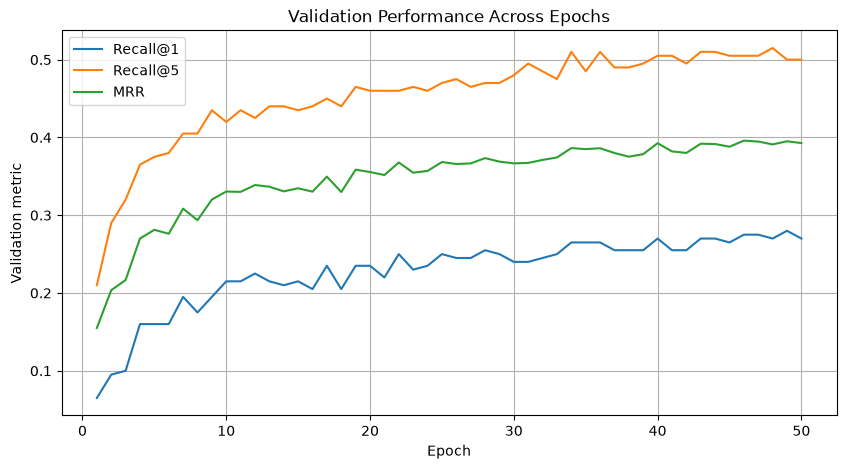

In [124]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

display(history_df.sort_values(
    "mrr", ascending=False
).head(10))

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["recall_at_1"],
         label="Recall@1")
plt.plot(history_df["epoch"], history_df["recall_at_5"],
         label="Recall@5")
plt.plot(history_df["epoch"], history_df["mrr"],
         label="MRR")
plt.xlabel("Epoch")
plt.ylabel("Validation metric")
plt.title("Validation Performance Across Epochs")
plt.legend()
plt.grid(True)
plt.show()


#### The results are clear: the controlled experiment is reproducible, but its retrieval accuracy is still substantially below the original baseline.

From your chart and table:
- The best validation MRR is approximately 0.3959 at epoch 46.
- At that epoch, Recall@1 is 27.5%, Recall@3 is 43.5%, and Recall@5 is 50.5%.
- Recall@5 improves quickly during the first few epochs, then mostly levels off around 50%.
- Training loss continues to fall, but validation performance improves much more slowly. This suggests a generalization problem, though the curve alone does not prove overfitting.
Compared with your original baseline (Recall@1 50%, Recall@5 72%, MRR 0.6032), this experiment is not an improvement.

![Generalisation](../../data/v2/docs/images/generalization.png)
![Overfitting](../../data/v2/docs/images/overfitting1.png)
![Overfitting](../../data/v2/docs/images/overfitting2.png)
![Overfitting](../../data/v2/docs/images/overfitting3.png)


#### Next step: diagnose the retrieval errors
Rather than change the model again, let's inspect which queries fail and what documents are retrieved instead. This will help us distinguish a training problem from a vocabulary or data problem.

##### Step 1 — Load the best checkpoint and inspect the top 5 results

##  Below cells  are experimental cells and more kind of for inspections

#### Do all 16,752 parameters change every time?
Not necessarily.
- The optimizer can update parameters that have gradients, according to the gradients and its update rules.
- Some parameters may remain unchanged in a particular update, for example if their gradients are zero or the update has no effect.
- The gradients and resulting updates can differ for every training batch.
Here's a simple way to observe this in your notebook:

In [112]:
# Save a copy of the model parameters before the update
before = {
    name: parameter.detach().clone()
    for name, parameter in model.named_parameters()
}

# Update the parameters
optimizer.step()

# Compare parameters before and after
for name, parameter in model.named_parameters():
    changed = (before[name] != parameter).sum().item()
    print(f"{name}: {changed} parameter values changed")

embedding.weight: 16108 parameter values changed
projection.weight: 512 parameter values changed
projection.bias: 16 parameter values changed


####  Display the first four batches. The order may differ each time you run Cell 1 because the pairs are shuffled.

In [103]:
import pandas as pd

for batch_number, start in enumerate(
    range(0, len(epoch_pairs), BATCH_SIZE), start=1
):
    pair_batch = epoch_pairs[start:start + BATCH_SIZE]

    batch_df = pd.DataFrame([
        {
            "document_id": pair["document_id"],
            "query": pair["query"]
        }
        for pair in pair_batch
    ])

    print(
        f"\nBatch {batch_number}: "
        f"{len(pair_batch)} pairs"
    )

    display(batch_df)


Batch 1: 25 pairs


,document_id,query
0,messaging-006,production considerations for dead letter queues
1,observability-007,what problem does sli slo and error budgets solve
2,java-006,help me understand garbage collection
3,performance-001,best practices for reusing expensive results i...
4,aws-008,help me understand iam roles and policies
5,database-003,what problem does acid transactions solve
6,security-009,help me understand secrets management
7,microservices-009,how do I implement api versioning
8,security-004,how do I implement authentication versus autho...
9,performance-004,give me guidance on load testing



Batch 2: 25 pairs


,document_id,query
0,aws-010,what problem does auto scaling solve
1,observability-003,what should I know about distributed tracing
2,containers-009,when should I use checking whether a pod is al...
3,spring-006,how does transaction management work
4,messaging-001,what should I know about kafka topics and part...
5,database-007,what problem does normalization solve
6,performance-010,production considerations for capacity planning
7,messaging-009,what problem does message ordering solve
8,aws-003,best practices for lambda functions
9,database-002,production considerations for sql joins



Batch 3: 25 pairs


,document_id,query
0,containers-005,what problem does kubernetes deployments solve
1,aws-006,give me guidance on application load balancer
2,messaging-007,when should I use message retry strategy
3,aws-007,when should I use isolating cloud resources wi...
4,containers-002,how does docker containers work
5,microservices-004,explain saga distributed transactions
6,database-001,give me guidance on database indexes
7,database-006,what problem does reusing database connections...
8,microservices-005,explain retry strategy
9,containers-004,how do I implement kubernetes pods



Batch 4: 25 pairs


,document_id,query
0,aws-001,how do I implement ec2 virtual machines
1,security-007,give me guidance on role-based access control
2,security-005,how does tls and https work
3,containers-008,best practices for changing pod replicas autom...
4,database-004,how does database locking work
5,java-008,explain streams
6,performance-007,what problem does api pagination solve
7,containers-006,give me guidance on kubernetes services
8,microservices-010,best practices for event-driven architecture
9,java-010,what should I know about records and immutability


#####   Prepare Batch 1 as tensors.Now we will take only the first 25 pairs and convert them into the padded tensors that the model accepts.The exact token dimensions depend on the longest query and document in this batch. Each row represents one text, and each value is a token ID. Padding makes the rows the same length within each tensor.

In [104]:
# Take only the first 25 pairs
pair_batch = epoch_pairs[:BATCH_SIZE]

# Convert pairs into the format expected by collate_batch
batch_dataset = SearchDataset(
    pair_batch,
    document_lookup
)

batch = collate_batch([
    batch_dataset[i]
    for i in range(len(batch_dataset))
])

print("Number of pairs:", len(pair_batch))
print("Query tensor shape:", batch["queries"].shape)
print("Document tensor shape:", batch["documents"].shape)

print("\nFirst 3 queries:")
for query in batch["query_texts"][:3]:
    print("-", query)

print("\nFirst 3 document IDs:")
print(batch["document_ids"][:3])

Number of pairs: 25
Query tensor shape: torch.Size([25, 11])
Document tensor shape: torch.Size([25, 53])

First 3 queries:
- production considerations for dead letter queues
- what problem does sli slo and error budgets solve
- help me understand garbage collection

First 3 document IDs:
['messaging-006', 'observability-007', 'java-006']


#####  Execute one complete training step.This is the important part. We will perform all eight operations for Batch 1 only, with print statements so you can inspect what happens.Forward pass, loss, gradients and parameter update

In [105]:
# --------------------------------------------------
# STEP 1: Clear gradients
# --------------------------------------------------

print("STEP 1: Clearing previous gradients")

optimizer.zero_grad()

print("Gradients cleared.")


# --------------------------------------------------
# STEP 2: Forward pass
# --------------------------------------------------

print("\nSTEP 2: Forward pass")

query_vectors = model(batch["queries"])
document_vectors = model(batch["documents"])

print("Query vectors shape:", query_vectors.shape)
print("Document vectors shape:", document_vectors.shape)

print("\nFirst query vector (16 values):")
print(query_vectors[0].detach())


# --------------------------------------------------
# STEP 3: Calculate similarity matrix
# --------------------------------------------------

print("\nSTEP 3: Calculate similarities")

similarities = query_vectors @ document_vectors.T

print("Similarity matrix shape:", similarities.shape)

print("\nFirst 5 queries vs first 5 documents:")
print(similarities[:5, :5].detach())


# --------------------------------------------------
# STEP 4: Scale similarities
# --------------------------------------------------

print("\nSTEP 4: Calculate logits")

logits = similarities / TEMPERATURE

print("Logits shape:", logits.shape)
print("\nFirst 5 x 5 logits:")
print(logits[:5, :5].detach())


# --------------------------------------------------
# STEP 5: Define correct document positions
# --------------------------------------------------

print("\nSTEP 5: Create targets")

targets = torch.arange(len(pair_batch))

print("Targets:", targets)


# --------------------------------------------------
# STEP 6: Calculate loss
# --------------------------------------------------

print("\nSTEP 6: Calculate loss")

loss = F.cross_entropy(logits, targets)

print("Loss:", loss.item())


# --------------------------------------------------
# STEP 7: Calculate gradients
# --------------------------------------------------

print("\nSTEP 7: Backpropagation")

loss.backward()

print("Gradients calculated.")

for name, parameter in model.named_parameters():
    if parameter.grad is not None:
        print(
            name,
            "| gradient shape:", tuple(parameter.grad.shape),
            "| gradient norm:", parameter.grad.norm().item()
        )


# --------------------------------------------------
# STEP 8: Update model parameters
# --------------------------------------------------

print("\nSTEP 8: Update parameters")

# Save a copy of one parameter before the update
parameter_name, parameter = next(
    (name, parameter)
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
)

parameter_before = parameter.detach().clone()

optimizer.step()

parameter_after = parameter.detach()

change = (parameter_after - parameter_before).abs().max().item()

print("Updated parameter:", parameter_name)
print("Largest absolute change in this parameter:", change)
print("\nBatch 1 training step completed.")

STEP 1: Clearing previous gradients
Gradients cleared.

STEP 2: Forward pass
Query vectors shape: torch.Size([25, 16])
Document vectors shape: torch.Size([25, 16])

First query vector (16 values):
tensor([ 0.5264,  0.0131, -0.0276, -0.1324,  0.2973,  0.0779,  0.1034, -0.3880,
        -0.0947,  0.3252,  0.2789, -0.4490, -0.1866,  0.1356, -0.0021, -0.0371])

STEP 3: Calculate similarities
Similarity matrix shape: torch.Size([25, 25])

First 5 queries vs first 5 documents:
tensor([[ 0.9741, -0.1492,  0.1180,  0.0955,  0.1030],
        [-0.0562,  0.9356,  0.0150, -0.2379, -0.5111],
        [ 0.1391, -0.2789,  0.9195,  0.1206,  0.4421],
        [-0.0474, -0.4265, -0.1421,  0.7257, -0.2322],
        [ 0.1185, -0.5561,  0.3244, -0.1078,  0.9550]])

STEP 4: Calculate logits
Logits shape: torch.Size([25, 25])

First 5 x 5 logits:
tensor([[13.9153, -2.1309,  1.6859,  1.3649,  1.4708],
        [-0.8026, 13.3654,  0.2140, -3.3991, -7.3021],
        [ 1.9866, -3.9841, 13.1352,  1.7234,  6.3155],
  